In [1]:
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt

### Generate and Prepare Data

In [2]:
from dataset_utils import generate_examples, get_eta, gaussian_data

In [3]:
priors = {
    'a_1': 0.7,
    'a_0': 0.3,
    'y_1_a_1': 0.7,
    'y_0_a_1': 0.3,
    'y_1_a_0': 0.4,
    'y_0_a_0': 0.6
}

dim = 2
var=2
train_samples = 10000
val_samples = 5000

#gaussian_data
samples, sensitive, labels, soft_labels, est_samples, est_sensitive, est_labels, est_soft_labels = gaussian_data(priors, dim, var, train_samples, val_samples)

# means, covars, samples, sensitive, labels = generate_examples(num_examples=train_samples, dim=dim, var=var, priors=priors)
# _,_, est_samples, est_sensitive, est_labels = generate_examples(num_examples=val_samples, dim=dim, var=var, means=list(means.values()), priors=priors)
# print(samples.shape, sensitive.shape, labels.shape)
# print(est_samples.shape, est_sensitive.shape, est_labels.shape)

(10000, 2) (10000,) (10000,)
(5000, 2) (5000,) (5000,)


In [4]:
# # We will now have a data of form (c,a,y), (c_est, a_est, y_est) and this is where our story begins
# soft_labels = []
# for i in range(samples.shape[0]):
#     temp_score = get_eta(samples[i], means, covars, priors, sensitive[i])  
#     # if labels[i] == 0:
#     #     temp_score = 1 - temp_score
#     soft_labels.append(temp_score)
# est_soft_labels = []
# for i in range(est_samples.shape[0]):
#     temp_score = get_eta(est_samples[i], means, covars, priors, est_sensitive[i])  
#     # if est_labels[i] == 0:
#     #     temp_score = 1 - temp_score
#     est_soft_labels.append(temp_score)

In [5]:
# Plot soft labels as a histogram
soft_labels = np.asarray(soft_labels)
est_soft_labels = np.asarray(est_soft_labels)
sensitive = np.asarray(sensitive)
est_sensitive = np.asarray(est_sensitive)
labels = np.asarray(labels)
est_labels = np.asarray(est_labels)
# Plot color coded histogram (group 0: red, group 1: blue)
plt.figure(figsize=(10, 5))
#plt.hist(soft_labels[np.where((labels == 0) & (sensitive == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0')
#plt.hist(soft_labels[np.where((labels == 1) & (sensitive == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1')
#plt.hist(soft_labels[np.where((labels == 0) & (sensitive == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0')
#plt.hist(soft_labels[np.where((labels == 1) & (sensitive == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1')


plt.figure(figsize=(10, 5))
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 0))[0]], bins=50, alpha=0.5, color='red', label='Group 0, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 0))[0]], bins=50, alpha=0.5, color='orange', label='Group 0, Label 1', density=True)
#plt.hist(train_c[np.where((train_y == 0) & (train_a == 1))[0]], bins=50, alpha=0.5, color='blue', label='Group 1, Label 0', density=True)
#plt.hist(train_c[np.where((train_y == 1) & (train_a == 1))[0]], bins=50, alpha=0.5, color='cyan', label='Group 1, Label 1', density=True)

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

In [6]:
# # plot the distribution
# def plot_distribution(samples, sensitive, labels, means, covars):
#     plt.figure(figsize=(10, 6))
#     color_00 = 'blue'
#     color_01 = 'orange'
#     color_10 = 'green'
#     color_11 = 'red'

#     indices_00 = np.where((labels == 0) & (sensitive == 0))[0]
#     indices_01 = np.where((labels == 0) & (sensitive == 1))[0]
#     indices_10 = np.where((labels == 1) & (sensitive == 0))[0]
#     indices_11 = np.where((labels == 1) & (sensitive == 1))[0]

#     plt.scatter(samples[indices_00, 0], samples[indices_00, 1], color=color_00, alpha=0.5, label='Label=0, Sensitive=0')
#     plt.scatter(samples[indices_01, 0], samples[indices_01, 1], color=color_01, alpha=0.5, label='Label=0, Sensitive=1')
#     plt.scatter(samples[indices_10, 0], samples[indices_10, 1], color=color_10, alpha=0.5, label='Label=1, Sensitive=0')
#     plt.scatter(samples[indices_11, 0], samples[indices_11, 1], color=color_11, alpha=0.5, label='Label=1, Sensitive=1')
#     plt.scatter(means['00'][0], means['00'][1], color=color_00, marker='x', s=100, label='Mean 00')
#     plt.scatter(means['01'][0], means['01'][1], color=color_01, marker='x', s=100, label='Mean 01')
#     plt.scatter(means['10'][0], means['10'][1], color=color_10, marker='x', s=100, label='Mean 10')
#     plt.scatter(means['11'][0], means['11'][1], color=color_11, marker='x', s=100, label='Mean 11')
#     plt.title('Distribution of Samples with Sensitive Attributes and Labels')
#     plt.xlabel('Feature 1')
#     plt.ylabel('Feature 2')
#     plt.legend()
#     plt.grid()
#     plt.show()
# plot_distribution(samples, sensitive, labels, means, covars)

### Baselines

In [7]:
# import sys
# import os
# import pandas as pd
# sys.path.append(os.path.join(os.getcwd(), 'FairPareto'))

# from FairPareto.fairpareto.core import FairParetoClassifier

# # Load your data (X should include the sensitive attribute column)
# # Modified the class to work with custom soft labels
# #feature_group = np.column_stack((samples, sensitive))
# data_df = pd.DataFrame(samples)
# data_df['sensitive'] = sensitive
# from sklearn.ensemble import RandomForestClassifier

# clf = FairParetoClassifier(soft=[
#     soft_labels[np.where(sensitive == 0)[0]],
#     soft_labels[np.where(sensitive == 1)[0]]
# ], sensitive_column='sensitive', gamma_values= list(np.linspace(0, 0.5, 31)))
# clf.fit(data_df, labels)

from baselines import train_mifpo

pareto_front = train_mifpo(
    samples,
    labels,
    sensitive,
    soft_labels,
)
print(pareto_front)

/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/xgboost/core.py:390: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


FairPareto: Starting fit process...
  - Data shape: (10000, 3)
  - Strategy: histogram, n_bins: 10, k: 2
  - Preparing dataset...
  - Group 0 size: 2887, Group 1 size: 7113
  - Using provided calibrated classifier...
  - Computing Pareto front...
    - Applying histogram binning...
    - Optimization parameters: n=10, m=10, alpha=0.711
    - Running optimization for 31 gamma values...


/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/vec.py:40: FutureWarning: 
    You didn't specify the order of the vec expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(vec_order_warning, FutureWarning)
/home/mohit/.conda/envs/llms/lib/python3.11/site-packages/cvxpy/atoms/affine/reshape.py:68: FutureWarning: 
    You didn't specify the order of the reshape expression. The default order
    used in CVXPY is Fortran ('F') order. This default will change to match NumPy's
    default order ('C') in a future version of CVXPY.
    To suppress this warning, please specify the order explicitly.
    
  warnings.warn(reshape_order_warning, FutureWarning)


  - Pareto front computed with 31 points
FairPareto: Fit complete!
{np.float64(0.0): np.float64(0.20338568424787756), np.float64(0.016666666666666666): np.float64(0.16255146915347116), np.float64(0.03333333333333333): np.float64(0.14836429085348973), np.float64(0.05): np.float64(0.15739074011556545), np.float64(0.06666666666666667): np.float64(0.14191987119894306), np.float64(0.08333333333333333): np.float64(0.14235901971775589), np.float64(0.1): np.float64(0.1208954312721762), np.float64(0.11666666666666667): np.float64(0.13998498317296018), np.float64(0.13333333333333333): np.float64(0.11741270780076674), np.float64(0.15): np.float64(0.12457222360729142), np.float64(0.16666666666666666): np.float64(0.1668521894630895), np.float64(0.18333333333333332): np.float64(0.1198066975816875), np.float64(0.2): np.float64(0.10963118272712621), np.float64(0.21666666666666667): np.float64(0.11500248852451284), np.float64(0.23333333333333334): np.float64(0.15096621826685794), np.float64(0.25): np.f

In [8]:
# from fairlearn.reductions import ExponentiatedGradient, DemographicParity, TruePositiveRateParity
# from sklearn.linear_model import LogisticRegression
# from tqdm import tqdm
# # Train Exp-grad
# # Repeat for DP
# eps_cls = {}
# # for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]):
# #     #constraint = DemographicParity()
# #     constraint = TruePositiveRateParity()
# #     mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
# #     mitigator.fit(samples, labels, sensitive_features=sensitive)
# #     eps_cls[eps] = mitigator
# for eps in tqdm([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3]):
#     constraint = DemographicParity()
#     #constraint = TruePositiveRateParity()
#     mitigator = ExponentiatedGradient(LogisticRegression(), constraint, eps=eps)
#     mitigator.fit(samples, labels, sensitive_features=sensitive)
#     eps_cls[eps] = mitigator

In [9]:
# from sklearn.metrics import accuracy_score
# from fairlearn.metrics import demographic_parity_difference, true_positive_rate_difference, true_positive_rate
# unfs = []
# errs = []
# eps = []

# def signed_dp(y_true, y_pred, sensitive_features):
#     group_0 = np.where(sensitive_features == 0)[0]
#     group_1 = np.where(sensitive_features == 1)[0]
#     pr_1_a0 = np.mean(y_pred[group_0])
#     pr_1_a1 = np.mean(y_pred[group_1])
#     return pr_1_a1 - pr_1_a0

# #unfair_model = LogisticRegression().fit(np.concatenate((train_x, train_a.reshape(-1,1)), axis=1), train_y)
# unfair_model = LogisticRegression().fit(np.concatenate((samples, sensitive.reshape(-1,1)), axis=1), labels)
# #preds = unfair_model.predict(np.concatenate((test_x, test_a.reshape(-1,1)), axis=1))
# preds = unfair_model.predict(np.concatenate((est_samples, est_sensitive.reshape(-1,1)), axis=1))
# #unfair_err = 1 - accuracy_score(test_y, preds)
# unfair_err = 1 - accuracy_score(est_labels, preds)
# #unfair_unf = demographic_parity_difference(est_labels, unfair_model.predict(est_samples), sensitive_features=est_sensitive)
# unfair_unf = signed_dp(est_labels, unfair_model.predict(np.concatenate((est_samples, est_sensitive.reshape(-1,1)), axis=1)), est_sensitive)
# #unfair_unf = true_positive_rate(test_y[np.where(test_a == 1)[0]], preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], preds[np.where(test_a == 0)[0]])
# #unfair_unf = true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], preds[np.where(est_sensitive == 0)[0]])

# # for e in eps_cls.keys():
# #     mitigated_test_preds = eps_cls[e].predict(test_x)
# #     #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
# #     #unfs.append(signed_dp(est_labels, mitigated_test_preds, est_sensitive))
# #     unfs.append(true_positive_rate(test_y[np.where(test_a == 1)[0]], mitigated_test_preds[np.where(test_a == 1)[0]]) - true_positive_rate(test_y[np.where(test_a == 0)[0]], mitigated_test_preds[np.where(test_a == 0)[0]]))
# #     errs.append(1 - accuracy_score(test_y, mitigated_test_preds))
# #     eps.append(e)

# for e in eps_cls.keys():
#     mitigated_test_preds = eps_cls[e].predict(est_samples)
#     #unfs.append(demographic_parity_difference(est_labels, mitigated_test_preds, sensitive_features=est_sensitive))
#     unfs.append(signed_dp(est_labels, mitigated_test_preds, est_sensitive))
#     #unfs.append(true_positive_rate(est_labels[np.where(est_sensitive == 1)[0]], mitigated_test_preds[np.where(est_sensitive == 1)[0]]) - true_positive_rate(est_labels[np.where(est_sensitive == 0)[0]], mitigated_test_preds[np.where(est_sensitive == 0)[0]]))
#     errs.append(1 - accuracy_score(est_labels, mitigated_test_preds))
#     eps.append(e)

# # Add the unfair model point
# unfs.append(unfair_unf)
# errs.append(unfair_err)
# eps.append(0)

# # Sort by errors
# temp = sorted(zip(unfs, errs, eps), key=lambda x: x[1])
# unfs, errs, eps = zip(*temp)
from baselines import train_exp_grad
unfs, errs, eps = train_exp_grad(
    samples,
    labels,
    sensitive,
    est_samples,
    est_labels,
    est_sensitive,
)

100%|██████████| 2/2 [00:00<00:00,  2.27it/s]


In [10]:
### Fairret
from baselines import train_fairret
from tqdm import tqdm

strength_values = [0, 0.001] #, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5]
points = {}
for val in tqdm(strength_values):
    points[val] = train_fairret(samples, soft_labels, sensitive, est_samples, est_labels, est_sensitive, fairness_strength=val, metric='DP')

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:15<00:00,  7.98s/it]


### Algorithm

In [11]:
from utils import soft_estimator, test_monotonicity

estimated_priors = soft_estimator(soft_labels, sensitive)
D_est = {
    'C': np.asarray(est_soft_labels),
    'A': est_sensitive
}
D = {
    'C': np.asarray(soft_labels),
    'A': sensitive
}

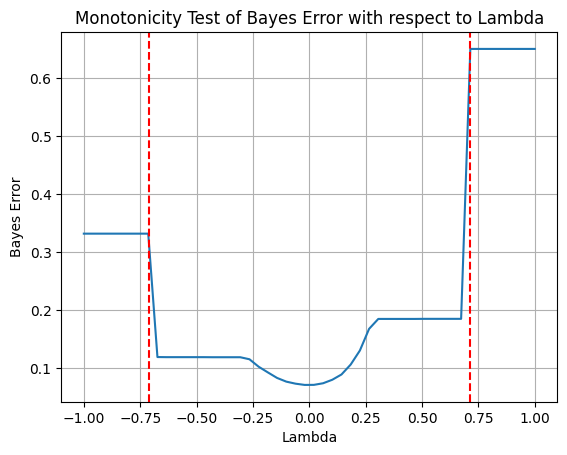

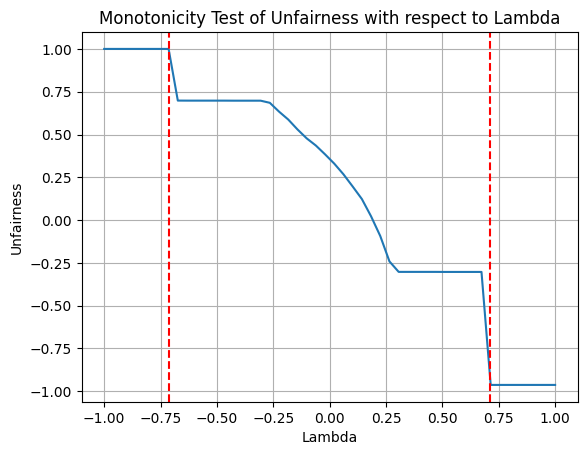

In [12]:
test_monotonicity(estimated_priors, D_est, 'DP')

In [13]:
from utils import return_tradeoff

true_tradeoff, true_bayes, true_unf = return_tradeoff(D_est, priors, constraint='DP', delta=0.0001, eps=0.0001)

0.07058368109023605 0.36035581199663425 0.7
lambda: 0.35, Alpha_0: 0, Alpha_1: 0.75, Error: 0.1846113311271554, Unfairness: -0.30269503546099286, Lam Min: 0, Lam Max: 0.7
lambda: 0.175, Alpha_0: 0.20833333333333331, Alpha_1: 0.625, Error: 0.09760773796392241, Unfairness: 0.06815242216612583, Lam Min: 0, Lam Max: 0.35
lambda: 0.26249999999999996, Alpha_0: 0.06250000000000006, Alpha_1: 0.6875, Error: 0.15492602789441623, Unfairness: -0.19422045918980646, Lam Min: 0.175, Lam Max: 0.35
lambda: 0.21874999999999997, Alpha_0: 0.13541666666666669, Alpha_1: 0.65625, Error: 0.11991742250790399, Unfairness: -0.04710181512200984, Lam Min: 0.175, Lam Max: 0.26249999999999996
lambda: 0.19687499999999997, Alpha_0: 0.17187500000000006, Alpha_1: 0.640625, Error: 0.10838561511472133, Unfairness: 0.00916937131866813, Lam Min: 0.175, Lam Max: 0.21874999999999997
lambda: 0.20781249999999996, Alpha_0: 0.15364583333333337, Alpha_1: 0.6484375, Error: 0.11337525794760012, Unfairness: -0.015915374444043673, Lam

In [14]:
est_tradeoff, est_bayes, est_unf = return_tradeoff(D_est, estimated_priors, constraint='DP', delta=0.0001, eps=0.0001)

0.07045607746794191 0.36035581199663425 0.7113
lambda: 0.35565, Alpha_0: 0, Alpha_1: 0.75, Error: 0.18448372750486125, Unfairness: -0.30269503546099286, Lam Min: 0, Lam Max: 0.7113
lambda: 0.177825, Alpha_0: 0.19202459300311736, Alpha_1: 0.625, Error: 0.10204496704768651, Unfairness: 0.04238971030171901, Lam Min: 0, Lam Max: 0.35565
lambda: 0.2667375, Alpha_0: 0.03803688950467604, Alpha_1: 0.6875, Error: 0.16921021258367558, Unfairness: -0.2484577473253996, Lam Min: 0.177825, Lam Max: 0.35565
lambda: 0.22228125, Alpha_0: 0.11503074125389667, Alpha_1: 0.65625, Error: 0.12880720216823538, Unfairness: -0.08777978122370467, Lam Min: 0.177825, Lam Max: 0.2667375
lambda: 0.200053125, Alpha_0: 0.15352766712850707, Alpha_1: 0.640625, Error: 0.11338624272945191, Unfairness: -0.016593340545738577, Lam Min: 0.177825, Lam Max: 0.22228125
lambda: 0.1889390625, Alpha_0: 0.17277613006581222, Alpha_1: 0.6328125, Error: 0.107996091559306, Unfairness: 0.010525303522057938, Lam Min: 0.177825, Lam Max: 0.

In [15]:
for key, val in est_tradeoff.items():
    print(f"Lambda: {key}, Estimated Trade-off: {val}")

Lambda: -1, Estimated Trade-off: [np.float64(0.07045607746794191), np.float64(0.36035581199663425), 0]
Lambda: 1, Estimated Trade-off: [np.float64(0.18448372750486125), np.float64(-0.30269503546099286), np.float64(0.35565)]
Lambda: 2, Estimated Trade-off: [np.float64(0.10204496704768651), np.float64(0.04238971030171901), np.float64(0.177825)]
Lambda: 3, Estimated Trade-off: [np.float64(0.16921021258367558), np.float64(-0.2484577473253996), np.float64(0.2667375)]
Lambda: 4, Estimated Trade-off: [np.float64(0.12880720216823538), np.float64(-0.08777978122370467), np.float64(0.22228125)]
Lambda: 5, Estimated Trade-off: [np.float64(0.11338624272945191), np.float64(-0.016593340545738577), np.float64(0.200053125)]
Lambda: 6, Estimated Trade-off: [np.float64(0.107996091559306), np.float64(0.010525303522057938), np.float64(0.1889390625)]
Lambda: 7, Estimated Trade-off: [np.float64(0.1103847464168477), np.float64(-0.001678086308450455), np.float64(0.19449609375)]
Lambda: 8, Estimated Trade-off: 

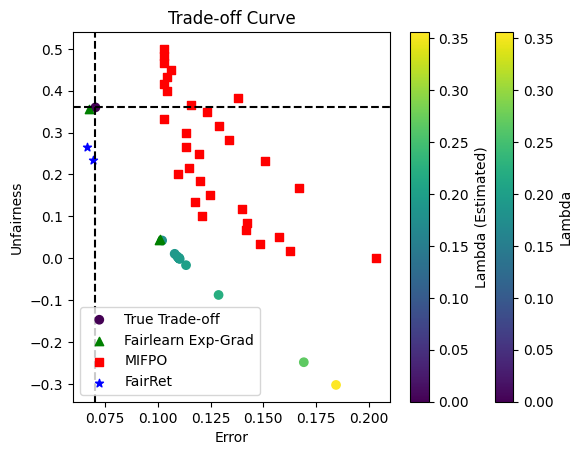

In [16]:
from utils import plot_tradeoff
plot_tradeoff(est_tradeoff, None, est_bayes, est_unf, {'exp_grad':(unfs, errs, eps), 'pareto':pareto_front, 'fairret':points})